# Analisis Penjualan Fashion Retail

## 1. Latar Belakang dan Pertanyaan Bisnis

Pada projek ini saya berperan sebagai analis di sebuah toko fashion bernama amorvincitomnia. Tim ingin mengetahui metode pembayaran apa yang paling sering dipakai pelanggan, dan bagaimana nilai serta waktu transaksinya, supaya tim dapat memutuskan metode pembayaran mana yang layak diberi diskon. Data dan skenario ini bersifat fiktif dan hanya asumsi saya pribadi.

### Pertanyaan Bisnis

| No | Pertanyaan | Hipotesis | Metrik | Kolom | 
|---|---|---|---|---|
| 1 | Metode pembayaran apa yang paling sering dipakai pelanggan? | Credit Card lebih sering dipakai daripada Cash, tetapi selisihnya kecil | Jumlah transaksi dan proporsi (%) per metode bayar | `Payment Method` | 
| 2 | Apakah pelanggan yang membayar dengan Credit Card memiliki nilai transaksi tipikal yang lebih tinggi daripada pelanggan Cash? | Credit Card memiliki nilai transaksi tipikal yang lebih tinggi | Median dan rata-rata nilai transaksi per metode, dibandingkan dengan dan tanpa nilai ekstrem | `Payment Method`, `Purchase Amount (USD)` | 
| 3 | Apakah nilai transaksi lebih tinggi pada awal bulan dibanding akhir bulan? | Awal bulan lebih tinggi karena gaji baru masuk | Median nilai transaksi dan jumlah transaksi per kelompok tanggal | `Date Purchase`, `Purchase Amount (USD)` | 
| 4 | Apakah pilihan metode pembayaran berbeda antara awal dan akhir bulan? | Proporsi Credit Card lebih tinggi di akhir bulan, saat uang tunai menipis | Proporsi tiap metode bayar di dalam masing-masing kelompok tanggal | `Date Purchase`, `Payment Method` |

### Definisi dan Asumsi

- **Transaksi:** satu baris data. Kolom nilai belanja adalah nilai per transaksi, bukan harga satuan produk, dan tidak ada kolom jumlah barang.
- **Awal bulan:** tanggal 1-15.
- **Akhir bulan:** tanggal 16 sampai akhir bulan.
- **Nilai kosong:** baris dengan nilai belanja kosong tidak dihitung di pertanyaan 2 dan 3.
- **Nilai ekstrem:** diperiksa di Tahap 3 (audit data), dan hasil analisis dibandingkan dengan dan tanpa nilai tersebut.
- **Hipotesis** hanyalah dugaan awal. Jika data tidak mendukung, hasilnya ditulis apa adanya.
## 2. Tentang Dataset
## 3. Audit Data
## 4. Pembersihan Data
## 5. Analisis dan EDA
## 6. Analisis Lanjutan
## 7. Insight dan Rekomendasi
## 8. Keterbatasan

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

FOLDER_MENTAH = Path("../data_mentah")
FOLDER_BERSIH = Path("../data_bersih")

print((FOLDER_MENTAH / "Fashion_Retail_Sales.csv").exists())   # ganti dengan nama filemu

True


In [2]:
df_toko = pd.read_csv(FOLDER_MENTAH / "Fashion_Retail_Sales.csv")

In [3]:
df_toko.shape

(3400, 6)

In [4]:
df_toko.head()

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method
0,4018,Handbag,4619.0,05-02-2023,NaN,Credit Card
1,4115,Tunic,2456.0,11-07-2023,2.0,Credit Card
2,4019,Tank Top,2102.0,23-03-2023,4.1,Cash
3,4097,Leggings,3126.0,15-03-2023,3.2,Cash
4,3997,Wallet,3003.0,27-11-2022,4.7,Cash


In [5]:
df_toko.tail()

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method
3395,4118,Shorts,37.0,09-07-2023,2.7,Cash
3396,4056,Slippers,176.0,16-03-2023,2.5,Cash
3397,3991,Onesie,NaN,03-10-2022,2.4,Credit Card
3398,4042,Sandals,128.0,01-01-2023,1.8,Cash
3399,4001,Backpack,115.0,22-03-2023,1.4,Cash


In [6]:
df_toko.sample(5, random_state=42)

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method
291,4003,Cardigan,131.0,04-01-2023,4.1,Credit Card
755,4050,Shorts,89.0,09-04-2023,NaN,Credit Card
2096,3998,Poncho,NaN,28-04-2023,2.3,Cash
432,4005,Flannel Shirt,191.0,23-03-2023,3.5,Cash
479,4073,Kimono,NaN,11-08-2023,2.0,Credit Card


In [7]:
df_toko.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3400 entries, 0 to 3399
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer Reference ID  3400 non-null   int64  
 1   Item Purchased         3400 non-null   object 
 2   Purchase Amount (USD)  2750 non-null   float64
 3   Date Purchase          3400 non-null   object 
 4   Review Rating          3076 non-null   float64
 5   Payment Method         3400 non-null   object 
dtypes: float64(2), int64(1), object(3)
memory usage: 159.5+ KB


In [8]:
kosong = pd.DataFrame({
    "jumlah": df_toko.isna().sum(),
    "persen": (df_toko.isna().mean() * 100).round(1),
})
kosong[kosong["jumlah"] > 0].sort_values("persen", ascending=False)

,jumlah,persen
Purchase Amount (USD),650,19.1
Review Rating,324,9.5


In [9]:
df_toko["harga_kosong"] = df_toko["Purchase Amount (USD)"].isna()
df_toko.groupby("Item Purchased")["harga_kosong"].mean().sort_values(ascending=False).head()

Item Purchased
Trousers      0.310345
Polo Shirt    0.271186
Swimsuit      0.257576
Romper        0.250000
Pajamas       0.246914
Name: harga_kosong, dtype: float64

In [10]:
df_toko.describe()

,Customer Reference ID,Purchase Amount (USD),Review Rating
count,3400.000000,2750.000000,3076.000000
mean,4039.660588,156.709818,2.999057
std,48.122583,419.536669,1.156505
min,3957.000000,10.000000,1.000000
25%,3997.000000,57.000000,2.000000
50%,4040.000000,110.000000,3.000000
75%,4081.000000,155.750000,4.000000
max,4122.000000,4932.000000,5.000000


In [11]:
df_toko.nunique()

Customer Reference ID    166
Item Purchased            50
Purchase Amount (USD)    234
Date Purchase            365
Review Rating             41
Payment Method             2
harga_kosong               2
dtype: int64

In [12]:
df_toko["Payment Method"].value_counts(dropna=False)

Payment Method
Credit Card    1770
Cash           1630
Name: count, dtype: int64

In [13]:
df_toko["Customer Reference ID"].value_counts().describe()   # transaksi per pelanggan

count    166.000000
mean      20.481928
std        4.375861
min       10.000000
25%       17.000000
50%       20.500000
75%       23.000000
max       34.000000
Name: count, dtype: float64

In [14]:
df_toko["Purchase Amount (USD)"].sort_values().tail(15)

3329   NaN
3333   NaN
3339   NaN
3343   NaN
3351   NaN
3352   NaN
3360   NaN
3363   NaN
3365   NaN
3374   NaN
3382   NaN
3385   NaN
3389   NaN
3390   NaN
3397   NaN
Name: Purchase Amount (USD), dtype: float64

In [15]:
df_toko["Purchase Amount (USD)"].value_counts(bins=10).sort_index()   # ada celah atau kelompok terpisah?

(5.077, 502.2]      2707
(502.2, 994.4]         0
(994.4, 1486.6]        0
(1486.6, 1978.8]       0
(1978.8, 2471.0]      11
(2471.0, 2963.2]       9
(2963.2, 3455.4]       6
(3455.4, 3947.6]       4
(3947.6, 4439.8]       6
(4439.8, 4932.0]       7
Name: count, dtype: int64

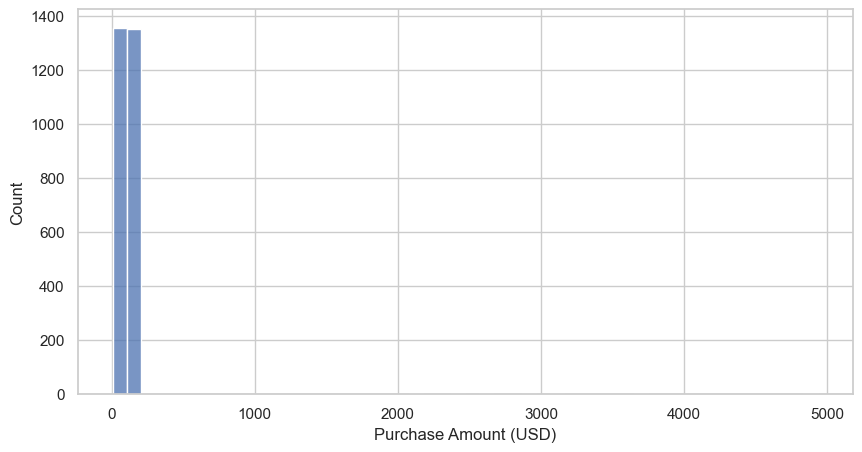

In [16]:
sns.histplot(data=df_toko, x="Purchase Amount (USD)", bins=50)
plt.show()

In [17]:
df_toko.duplicated().sum()

np.int64(0)

In [18]:
kolom_kunci = ["Customer Reference ID", "Item Purchased", "Date Purchase"]
df_toko[df_toko.duplicated(subset=kolom_kunci, keep=False)].sort_values(kolom_kunci)

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method,harga_kosong
2058,3983,Wallet,NaN,22-09-2023,5.0,Cash,True
2170,3983,Wallet,19.0,22-09-2023,2.4,Cash,False
819,4064,Sandals,154.0,08-10-2022,2.7,Cash,False
2720,4064,Sandals,131.0,08-10-2022,3.7,Cash,False
2479,4107,Swimsuit,110.0,02-07-2023,4.1,Cash,False
2686,4107,Swimsuit,112.0,02-07-2023,1.4,Credit Card,False


In [19]:
df_toko["Item Purchased"].nunique()

50

In [20]:
df_toko["Item Purchased"].str.strip().str.lower().nunique()

50

In [21]:
tanggal_uji = pd.to_datetime(df_toko["Date Purchase"], format="%d-%m-%Y", errors="coerce")

In [22]:
tanggal_uji.isna().sum()                              # berapa yang gagal terbaca

np.int64(0)

In [23]:
tanggal_uji.min(), tanggal_uji.max()

(Timestamp('2022-10-02 00:00:00'), Timestamp('2023-10-01 00:00:00'))

In [24]:
tanggal_uji.dt.to_period("M").value_counts().sort_index()

Date Purchase
2022-10    309
2022-11    238
2022-12    306
2023-01    292
2023-02    251
2023-03    277
2023-04    295
2023-05    308
2023-06    262
2023-07    303
2023-08    301
2023-09    253
2023-10      5
Freq: M, Name: count, dtype: int64